# Notebook 04 · Modelado de tópicos

**Autores:** Isabel Cristina Morales Parra – Jaime Esteban Bejarano Caldas

**Objetivo que cubre:** objetivo específico 6. Se identifican los temas de las reseñas de forma no supervisada y se contrastan con las dimensiones del servicio del notebook 03.

## 0. Vocabulario común

Para que las métricas sean comparables entre métodos, **todos los modelos usan el mismo vocabulario** y la misma definición de coocurrencia (a nivel de reseña). Se trabaja con las 17.263 reseñas, sobre el texto normalizado del notebook 01, con tres filtros adicionales:
- `min_df=10`: se descartan los términos que aparecen en menos de 10 reseñas.
- `max_df=0.5`: se descartan los términos que aparecen en más de la mitad de las reseñas.
- **Palabras vacías del dominio:** se eliminan términos genéricos de valoración o de relleno (*hotel*, *stay*, *good*, *great*, *recommend*…). Aparecen en todos los temas y no ayudan a distinguirlos; si se conservaran, cada tópico se llenaría de elogios genéricos.

Se construyen dos representaciones del mismo vocabulario: **conteos** para LDA, que es un modelo probabilístico de frecuencias, y **TF-IDF** para NMF y para SVD + KMeans.

In [2]:
%load_ext autoreload
%autoreload 2

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))
from src.topicos import terminos_principales, npmi_documental, diversidad, estabilidad_jaccard

RUTA_FIGURAS = RAIZ / "figures"
RUTA_RESULTADOS = RAIZ / "results"
SEMILLA = 42
sns.set_theme(style="whitegrid", palette="deep")

df_en = pd.read_csv(RAIZ / "data" / "processed" / "resenas_en_depuradas.csv")

VACIAS_DOMINIO = ["hotel", "stay", "good", "great", "nice", "not", "no", "place", "time", "day",
                  "excellent", "amazing", "wonderful", "really", "recommend", "experience", "thank",
                  "visit", "definitely", "highly", "love", "like", "perfect", "awesome", "best",
                  "beautiful", "lovely", "overall", "fantastic", "everything"]

vectorizador_conteos = CountVectorizer(min_df=10, max_df=0.5, stop_words=VACIAS_DOMINIO, token_pattern=r"\S+")
C = vectorizador_conteos.fit_transform(df_en["texto_limpio"])
vocabulario = vectorizador_conteos.get_feature_names_out()

T = TfidfVectorizer(vocabulary=vectorizador_conteos.vocabulary_, sublinear_tf=True,
                    token_pattern=r"\S+").fit_transform(df_en["texto_limpio"])

print(f"Matriz documento–término: {C.shape[0]:,} reseñas × {C.shape[1]:,} términos")
print(f"Proporción de celdas distintas de cero: {C.nnz / (C.shape[0] * C.shape[1]):.2%}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Matriz documento–término: 17,263 reseñas × 4,088 términos
Proporción de celdas distintas de cero: 0.68%


**Resultado.** El vocabulario común tiene **4.088 términos** para 17.263 reseñas. Solo el 0,68 % de las celdas de la matriz documento–término son distintas de cero: cada reseña usa unas 28 de las 4.088 palabras posibles. Por eso la matriz se almacena en formato disperso, que solo guarda los valores distintos de cero.

## 1. Comparación de métodos

| Método | Representación | Idea |
|:--|:--|:--|
| **NMF** (Lee y Seung, 1999) | TF-IDF | Factoriza la matriz documento–término en dos matrices no negativas: documentos × tópicos y tópicos × términos. Cada reseña es una suma ponderada de tópicos |
| **LDA** (Blei, Ng y Jordan, 2003) | Conteos | Modelo probabilístico: cada reseña es una mezcla de tópicos y cada tópico es una distribución de probabilidad sobre palabras |
| **SVD + KMeans** (línea base) | TF-IDF | Reduce la matriz a 100 dimensiones latentes (SVD) y agrupa las reseñas (KMeans). Cada reseña pertenece a **un solo** grupo |

Se prueban **K = 8 y K = 12** tópicos, con semilla fija (42). Cada configuración se entrena una segunda vez con otra semilla (7) para medir la estabilidad. Se reportan:
- **NPMI**: coherencia.
- **Diversidad@10**: proporción de términos únicos.
- **Estabilidad Jaccard**: similitud entre ejecuciones con semillas distintas.
- **NMI externo**: información mutua normalizada entre el tópico dominante de cada reseña y su calificación.
- **Tiempo de ajuste.**

**Advertencia sobre el NMI:** la calificación no es una «etiqueta verdadera» de los tópicos. Una reseña sobre el desayuno puede tener cualquier calificación. El NMI solo indica cuánto se relacionan los temas con la satisfacción.

Listo: NMF + TF-IDF, K=8 (5.2 s)
Listo: LDA + conteos, K=8 (209.3 s)
Listo: SVD + KMeans, K=8 (3.4 s)
Listo: NMF + TF-IDF, K=12 (3.4 s)
Listo: LDA + conteos, K=12 (204.8 s)
Listo: SVD + KMeans, K=12 (3.3 s)


,Método,K,NPMI-doc,Diversidad@10,Estabilidad Jaccard,NMI externo (Rating),Tiempo ajuste (s)
0,NMF + TF-IDF,8,0.160,0.888,0.955,0.066,5.213
1,LDA + conteos,8,0.120,0.662,0.586,0.095,209.293
2,SVD + KMeans,8,0.141,0.625,0.648,0.092,3.428
3,NMF + TF-IDF,12,0.163,0.892,0.576,0.059,3.365
4,LDA + conteos,12,0.134,0.600,0.432,0.113,204.764
5,SVD + KMeans,12,0.126,0.517,0.695,0.078,3.254


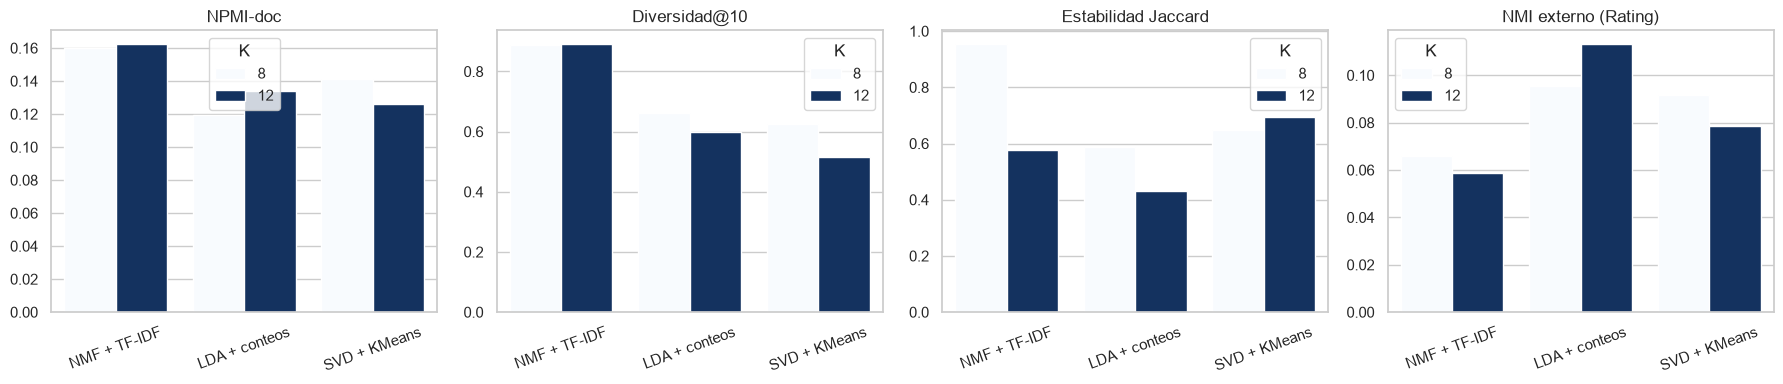


NMF + TF-IDF (K = 8)
  T0: clean, room, pool, comfortable, breakfast, spacious, swimming, buffet, neat, bed
  T1: service, food, quality, restaurant, delicious, provide, enjoy, customer, serve, ambience
  T2: room, night, need, breakfast, restaurant, check, water, work, star, buffet
  T3: helpful, friendly, especially, kind, extremely, location, help, food, professional, restaurant
  T4: hospitality, team, family, special, come, friend, mr, care, feel, warm
  T5: view, mountain, pokhara, lake, resort, range, lodge, sunrise, annapurna, balcony
  T6: kathmandu, city, location, thamel, locate, away, nepal, hyatt, close, walk
  T7: elephant, safari, jungle, resort, lodge, guide, river, tiger, activity, chitwan

LDA + conteos (K = 8)
  T0: lodge, elephant, jungle, safari, guide, food, river, tiger, activity, resort
  T1: view, resort, mountain, pokhara, lake, room, food, lodge, enjoy, forest
  T2: room, night, check, water, breakfast, ask, come, book, leave, hour
  T3: room, star, service,

In [3]:
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF, LatentDirichletAllocation, TruncatedSVD
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import normalize

def ajustar(metodo, K, semilla):
    """Entrena un modelo y devuelve (pesos documento–tópico, pesos tópico–término, tiempo en segundos)."""
    inicio = time.perf_counter()
    if metodo == "NMF + TF-IDF":
        modelo = NMF(n_components=K, init="random", max_iter=600, random_state=semilla)
        W = modelo.fit_transform(T)
        H = modelo.components_
    elif metodo == "LDA + conteos":
        modelo = LatentDirichletAllocation(n_components=K, max_iter=20, learning_method="batch", random_state=semilla)
        W = modelo.fit_transform(C)
        H = modelo.components_
    else:  # SVD + KMeans
        Z = normalize(TruncatedSVD(n_components=100, random_state=semilla).fit_transform(T))
        grupos = KMeans(n_clusters=K, n_init=10, random_state=semilla).fit_predict(Z)
        H = np.vstack([np.asarray(T[grupos == k].mean(axis=0)).ravel() for k in range(K)])  # centroide en el espacio de términos
        W = np.eye(K)[grupos]
    return W, H, time.perf_counter() - inicio

filas, modelos_topicos = [], {}
for K in [8, 12]:
    for metodo in ["NMF + TF-IDF", "LDA + conteos", "SVD + KMeans"]:
        W, H, duracion = ajustar(metodo, K, SEMILLA)
        _, H2, _ = ajustar(metodo, K, 7)
        idx, palabras = terminos_principales(H, vocabulario, 10)
        idx2, _ = terminos_principales(H2, vocabulario, 10)
        npmi, npmi_topicos = npmi_documental(idx, C)
        filas.append({"Método": metodo, "K": K, "NPMI-doc": npmi, "Diversidad@10": diversidad(idx),
                      "Estabilidad Jaccard": estabilidad_jaccard(idx, idx2),
                      "NMI externo (Rating)": normalized_mutual_info_score(df_en["Rating"], W.argmax(axis=1)),
                      "Tiempo ajuste (s)": duracion})
        modelos_topicos[(metodo, K)] = {"W": W, "H": H, "palabras": palabras, "npmi_topicos": npmi_topicos}
        print(f"Listo: {metodo}, K={K} ({duracion:.1f} s)")

tabla_topicos = pd.DataFrame(filas)
display(tabla_topicos.round(3))
tabla_topicos.to_csv(RUTA_RESULTADOS / "04_comparacion_metodos_topicos.csv", index=False)

# --- Figura: métricas por método y K ---
metricas = ["NPMI-doc", "Diversidad@10", "Estabilidad Jaccard", "NMI externo (Rating)"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metrica in zip(axes, metricas):
    sns.barplot(data=tabla_topicos, x="Método", y=metrica, hue="K", palette="Blues", ax=ax)
    ax.set(title=metrica, xlabel="", ylabel="")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "04_comparacion_metodos_topicos.png", dpi=150, bbox_inches="tight")
plt.show()

# --- Términos principales de cada método con K = 8 ---
for metodo in ["NMF + TF-IDF", "LDA + conteos", "SVD + KMeans"]:
    print(f"\n{metodo} (K = 8)")
    for i, palabras in enumerate(modelos_topicos[(metodo, 8)]["palabras"]):
        print(f"  T{i}: {', '.join(palabras)}")

**Resultado.**

| Método | K | NPMI ↑ | Diversidad@10 ↑ | Estabilidad ↑ | NMI externo | Tiempo (s) ↓ | Interpretación |
|:--|--:|--:|--:|--:|--:|--:|:--|
| **NMF + TF-IDF** | **8** | **0,160** | **0,888** | **0,955** | 0,066 | 5 | Tópicos coherentes, distintos entre sí y reproducibles. Es la mejor configuración en tres de las cuatro métricas |
| NMF + TF-IDF | 12 | 0,163 | 0,892 | 0,576 | 0,059 | 3 | Igual de coherente y diverso, pero inestable: con 12 tópicos, la división depende de la semilla |
| LDA + conteos | 8 | 0,120 | 0,662 | 0,586 | 0,095 | 209 | Las palabras frecuentes (*room*, *food*, *service*) se repiten en casi todos los tópicos. Es 40 veces más lento |
| LDA + conteos | 12 | 0,134 | 0,600 | 0,432 | 0,113 | 205 | Mayor NMI, pero la configuración menos estable |
| SVD + KMeans | 8 | 0,141 | 0,625 | 0,648 | 0,092 | 3 | Línea base competitiva en coherencia, pero redundante |
| SVD + KMeans | 12 | 0,126 | 0,517 | 0,695 | 0,078 | 3 | La menos diversa |

**Selección: NMF con K = 8.**
- **Por qué NMF:** obtiene la mayor coherencia y diversidad con los dos valores de K. LDA tiende a repartir las palabras más frecuentes entre todos los tópicos, porque modela conteos: una palabra muy frecuente tiene alta probabilidad en cualquier tópico. NMF sobre TF-IDF reduce el peso de esas palabras.
- **Por qué K = 8:** con K = 12, NMF mantiene la coherencia, pero su estabilidad cae de 0,955 a 0,576. Los 4 tópicos adicionales no son una estructura robusta de los datos, sino divisiones que cambian según la semilla.

**El mejor valor numérico no basta para elegir.** LDA con K = 12 tiene el mayor NMI externo (0,113). Sin embargo, el NMI no mide la calidad de los tópicos: mide cuánto se alinean con la calificación, que no es una etiqueta temática. Además, los valores de NMI son bajos para todos los métodos (≤ 0,11). Es lo esperable: de lo que habla una reseña (el safari, la vista) es en gran medida independiente de cuán satisfecho quedó el huésped.

**Los tres métodos coinciden en los temas más definidos:** el safari en Chitwan (*elephant, jungle, tiger*), las vistas de Pokhara (*mountain, lake, annapurna*) y los problemas de la habitación (*night, check, water*). Que métodos distintos encuentren los mismos temas es evidencia de que esos temas existen en los datos.

## 2. Interpretación de los tópicos (NMF, K = 8)

A cada tópico se le asigna una etiqueta a partir de sus términos principales. **La etiqueta es una interpretación humana, no un resultado del modelo.** Luego se analiza:
1. **La relación con el sentimiento:** la proporción media de cada tópico en las reseñas negativas, neutrales y positivas.
2. **La coherencia de cada tópico (NPMI)**, para identificar el tópico más difícil de interpretar.
3. **Reseñas con más de un tema:** las reseñas en las que dos tópicos tienen cada uno al menos el 30 % del peso.

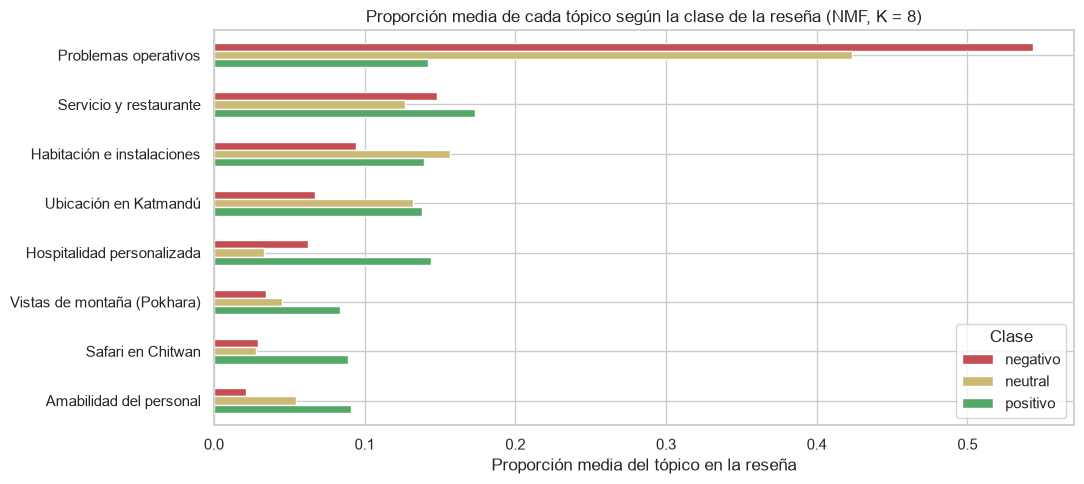

clase_B,negativo,neutral,positivo,Razón negativo / positivo
Problemas operativos,0.544,0.423,0.142,3.825
Servicio y restaurante,0.148,0.127,0.173,0.856
Habitación e instalaciones,0.094,0.156,0.139,0.676
Ubicación en Katmandú,0.067,0.132,0.138,0.483
Hospitalidad personalizada,0.063,0.033,0.144,0.435
Vistas de montaña (Pokhara),0.035,0.045,0.083,0.416
Safari en Chitwan,0.029,0.028,0.089,0.327
Amabilidad del personal,0.021,0.054,0.091,0.230


Coherencia por tópico (de menor a mayor):


,Tópico,NPMI,Términos principales
3,Amabilidad del personal,0.049,"helpful, friendly, especially, kind, extremely..."
1,Servicio y restaurante,0.050,"service, food, quality, restaurant, delicious,..."
4,Hospitalidad personalizada,0.095,"hospitality, team, family, special, come, frie..."
6,Ubicación en Katmandú,0.120,"kathmandu, city, location, thamel, locate, awa..."
2,Problemas operativos,0.128,"room, night, need, breakfast, restaurant, chec..."
0,Habitación e instalaciones,0.139,"clean, room, pool, comfortable, breakfast, spa..."
5,Vistas de montaña (Pokhara),0.263,"view, mountain, pokhara, lake, resort, range, ..."
7,Safari en Chitwan,0.438,"elephant, safari, jungle, resort, lodge, guide..."



Reseñas con dos tópicos de al menos 30 % cada uno: 4,592 (26.6%)

[3★] Habitación e instalaciones (39%) + Servicio y restaurante (34%)
    Small, tiny rooms  what they call as Heritage deluxe, can be claustrophobic for some. Clean hotel, service was better at restaurants compared to front desk. Breakfast spread was good with nice flavors. The other restaurant Chimney was just ok with very limited food options. ...

[4★] Ubicación en Katmandú (47%) + Problemas operativos (37%)
    Whilst previous reviews on this hotel indicated that the staff were unfriendly, I found quite the contrary.  One of our party was feeling quite ill and they arranged a doctor quickly and efficiently and followed up regularly to see if there was any further assistance they could provide.  Thamel is only a short distance away.This was the most expensive hotel we stayed at in Nepal, but we felt it wa ...

[5★] Servicio y restaurante (60%) + Hospitalidad personalizada (32%)
    We had excellent time here. Great p

In [4]:
nmf8 = modelos_topicos[("NMF + TF-IDF", 8)]
W = nmf8["W"]

etiquetas = {
    0: "Habitación e instalaciones",
    1: "Servicio y restaurante",
    2: "Problemas operativos",
    3: "Amabilidad del personal",
    4: "Hospitalidad personalizada",
    5: "Vistas de montaña (Pokhara)",
    6: "Ubicación en Katmandú",
    7: "Safari en Chitwan",
}

# --- Proporción de cada tópico en cada reseña ---
suma = W.sum(axis=1, keepdims=True)
proporciones = pd.DataFrame(np.divide(W, suma, out=np.full_like(W, np.nan), where=suma > 0),
                            columns=list(etiquetas.values()))
proporciones["clase_B"] = df_en["clase_B"].values

# --- 1. Tópicos y sentimiento ---
por_clase = proporciones.groupby("clase_B")[list(etiquetas.values())].mean().T[["negativo", "neutral", "positivo"]]
por_clase["Razón negativo / positivo"] = por_clase["negativo"] / por_clase["positivo"]
por_clase = por_clase.sort_values("Razón negativo / positivo", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))
por_clase[["negativo", "neutral", "positivo"]].plot(kind="barh", color=["#C44E52", "#CCB974", "#55A868"], ax=ax)
ax.set(title="Proporción media de cada tópico según la clase de la reseña (NMF, K = 8)",
       xlabel="Proporción media del tópico en la reseña", ylabel="")
ax.invert_yaxis()
ax.legend(title="Clase")
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "04_topicos_por_sentimiento.png", dpi=150, bbox_inches="tight")
plt.show()
display(por_clase.round(3))

# --- 2. Coherencia por tópico ---
coherencia = pd.DataFrame({
    "Tópico": list(etiquetas.values()),
    "NPMI": nmf8["npmi_topicos"],
    "Términos principales": [", ".join(p) for p in nmf8["palabras"]],
}).sort_values("NPMI")
print("Coherencia por tópico (de menor a mayor):")
display(coherencia.round(3))

# --- 3. Reseñas con más de un tema ---
ordenadas = np.sort(proporciones[list(etiquetas.values())].fillna(0).values, axis=1)
mixtas = np.where((ordenadas[:, -1] >= 0.30) & (ordenadas[:, -2] >= 0.30))[0]
print(f"\nReseñas con dos tópicos de al menos 30 % cada uno: {len(mixtas):,} ({len(mixtas) / len(df_en):.1%})")
rng = np.random.default_rng(SEMILLA)
for i in rng.choice(mixtas, size=3, replace=False):
    top2 = proporciones.iloc[i][list(etiquetas.values())].astype(float).nlargest(2)
    print(f"\n[{df_en.loc[i, 'Rating']}★] {' + '.join(f'{t} ({p:.0%})' for t, p in top2.items())}")
    print("   ", df_en.loc[i, "Review"][:400], "...")

por_clase.to_csv(RUTA_RESULTADOS / "04_topicos_por_sentimiento.csv")
coherencia.to_csv(RUTA_RESULTADOS / "04_coherencia_por_topico.csv", index=False)

**Resultado 1: el modelado de tópicos encontró, sin etiquetas, el tema de la insatisfacción.** El tópico *Problemas operativos* (*room, night, need, check, water, work*) ocupa en promedio el **54,4 % de las reseñas negativas**, el 42,3 % de las neutrales y solo el 14,2 % de las positivas (razón 3,8). Es el único tópico más presente en las reseñas negativas que en las positivas. El modelo nunca vio las calificaciones; aun así, aisló el vocabulario de las fallas: el check-in, el agua y lo que «no funciona». Este resultado es coherente con las dimensiones de limpieza e instalaciones del notebook 03, y con los términos distintivos del notebook 01.

**Resultado 2: los tópicos positivos son de trato y de destino.** *Amabilidad del personal* (razón 0,23), *Safari en Chitwan* (0,33), *Vistas de montaña* (0,42) y *Hospitalidad personalizada* (0,44) están mucho más presentes en las reseñas positivas. Las experiencias satisfactorias se narran a partir del entorno natural y del trato humano.

**Resultado 3: tópico difícil de interpretar.** *Amabilidad del personal* tiene la menor coherencia (NPMI = 0,049). Sus términos (*helpful, friendly, especially, kind, extremely, location, food, professional*) mezclan adjetivos de elogio con **intensificadores** (*especially*, *extremely*) y con sustantivos de otros temas (*location*, *food*). No es un tema, sino un **registro**: la forma genérica de elogiar. Estas palabras aparecen en muchas reseñas, pero no necesariamente juntas, y por eso su coherencia es baja. *Servicio y restaurante* (NPMI = 0,050) tiene el mismo problema. En contraste, los tópicos de destino son los más coherentes: *Safari* (0,438) y *Vistas* (0,263) usan un vocabulario muy específico que siempre aparece junto.

**Resultado 4: reseñas con más de un tema.** El 26,6 % de las reseñas (4.592) combina dos tópicos con al menos 30 % cada uno, lo que confirma que una reseña es una **mezcla** de temas. Los tres ejemplos:
1. **[3★] Habitación (39 %) + Servicio (34 %):** critica las habitaciones (*small, tiny rooms… claustrophobic*) y elogia el restaurante. Es la ambivalencia típica de una reseña neutral.
2. **[4★] Ubicación (47 %) + Problemas operativos (37 %):** es una reseña positiva que menciona problemas (*staff unfriendly*, *feeling ill*, *doctor*) para **contradecirlos** («I found quite the contrary»). Los tópicos capturan **de qué se habla, no qué se opina**: hablar de un problema no implica quejarse.
3. **[5★] Servicio (60 %) + Hospitalidad personalizada (32 %):** el huésped nombra a los empleados (*Shagun, Surendra, Ganaraj*), un rasgo de las reseñas satisfechas identificado en el notebook 01.

## 3. Prueba de intrusión de palabras

Las métricas automáticas no garantizan que un tópico sea interpretable para una persona. La **prueba de intrusión de palabras** (Chang et al., 2009) lo evalúa directamente: para cada tópico se presentan sus 5 términos principales junto con una **palabra intrusa**, que tiene un peso alto en otro tópico y bajo en este. El orden de las palabras se mezcla. El evaluador debe identificar la intrusa sin conocer la respuesta. Si el tópico es coherente, la intrusa «salta a la vista».

**Precisión del modelo** = proporción de tópicos en los que el evaluador identificó la intrusa. Se compara con la coherencia NPMI de cada tópico, para ver si la medida automática y la lectura humana coinciden.

In [6]:
rng = np.random.default_rng(SEMILLA)
H = nmf8["H"]
rangos = np.argsort(np.argsort(-H, axis=1), axis=1)  # posición de cada término en cada tópico (0 = el más importante)

prueba, claves = [], {}
for t in range(H.shape[0]):
    principales = list(np.argsort(-H[t])[:5])
    # Intrusa: entre los 10 principales de otro tópico y fuera de los 100 principales de este
    candidatas = [j for otro in range(H.shape[0]) if otro != t
                  for j in np.argsort(-H[otro])[:10] if rangos[t, j] > 100]
    intrusa = rng.choice(candidatas)
    opciones = [vocabulario[j] for j in principales] + [vocabulario[intrusa]]
    rng.shuffle(opciones)
    prueba.append({"Tópico": t, "Opciones": ", ".join(opciones)})
    claves[t] = vocabulario[intrusa]

display(pd.DataFrame(prueba))
for fila in prueba:
    print(f"Tópico {fila['Tópico']}: {fila['Opciones']}")

,Tópico,Opciones
0,0,"comfortable, pool, clean, breakfast, room, serve"
1,1,"service, quality, spacious, food, delicious, r..."
2,2,"room, night, restaurant, need, city, breakfast"
3,3,"helpful, pokhara, extremely, especially, frien..."
4,4,"team, hospitality, come, special, friendly, fa..."
5,5,"ambience, mountain, pokhara, resort, lake, view"
6,6,"city, location, activity, thamel, kathmandu, l..."
7,7,"check, resort, lodge, jungle, elephant, safari"


Tópico 0: comfortable, pool, clean, breakfast, room, serve
Tópico 1: service, quality, spacious, food, delicious, restaurant
Tópico 2: room, night, restaurant, need, city, breakfast
Tópico 3: helpful, pokhara, extremely, especially, friendly, kind
Tópico 4: team, hospitality, come, special, friendly, family
Tópico 5: ambience, mountain, pokhara, resort, lake, view
Tópico 6: city, location, activity, thamel, kathmandu, locate
Tópico 7: check, resort, lodge, jungle, elephant, safari


**Instrucciones:** para cada tópico, el evaluador escribe en el diccionario `respuestas` la palabra que considera intrusa, **sin consultar las claves**. Evaluadores: Isabel Cristina Morales Parra y Jaime Esteban Bejarano Caldas.

In [7]:
respuestas = {
    "Isabel": {0: "breakfast", 1: "spacious", 2: "breakfast", 3: "pokhara", 4: "come", 5: "resort", 6: "thamel", 7: "resort"},
    # "Esteban": {0: "", 1: "", ...},   # agregar si Esteban también responde
}

filas = []
for evaluador, resp in respuestas.items():
    for t in range(len(claves)):
        filas.append({"Evaluador": evaluador, "Tópico": etiquetas[t], "Respuesta": resp[t],
                      "Intrusa real": claves[t], "Acierto": resp[t].strip().lower() == claves[t]})
resultado_intrusion = pd.DataFrame(filas)
display(resultado_intrusion)

precision = resultado_intrusion.groupby("Tópico")["Acierto"].mean()
comparacion_humana = pd.DataFrame({"Precisión humana": precision,
                                   "NPMI": coherencia.set_index("Tópico")["NPMI"]}).sort_values("NPMI")
print(f"Precisión global de la prueba de intrusión: {resultado_intrusion['Acierto'].mean():.0%}")
display(comparacion_humana.round(3))
resultado_intrusion.to_csv(RUTA_RESULTADOS / "04_prueba_intrusion.csv", index=False)

,Evaluador,Tópico,Respuesta,Intrusa real,Acierto
0,Isabel,Habitación e instalaciones,breakfast,serve,False
1,Isabel,Servicio y restaurante,spacious,spacious,True
2,Isabel,Problemas operativos,breakfast,city,False
3,Isabel,Amabilidad del personal,pokhara,pokhara,True
4,Isabel,Hospitalidad personalizada,come,friendly,False
5,Isabel,Vistas de montaña (Pokhara),resort,ambience,False
6,Isabel,Ubicación en Katmandú,thamel,activity,False
7,Isabel,Safari en Chitwan,resort,check,False


Precisión global de la prueba de intrusión: 25%


,Precisión humana,NPMI
Tópico,,
Amabilidad del personal,1.0,0.049
Servicio y restaurante,1.0,0.050
Hospitalidad personalizada,0.0,0.095
Ubicación en Katmandú,0.0,0.120
Problemas operativos,0.0,0.128
Habitación e instalaciones,0.0,0.139
Vistas de montaña (Pokhara),0.0,0.263
Safari en Chitwan,0.0,0.438


**Resultado.** La precisión de la prueba de intrusión fue del **25 %** (2 de 8 tópicos). Es apenas superior al azar: con 6 opciones, elegir al azar acierta en 1 de cada 6 casos (16,7 %).

**Interpretación.**
1. **Las intrusas eran plausibles.** El criterio de selección garantizó que la intrusa fuera ajena al tópico *en los pesos del modelo*, pero no que lo fuera *para un lector*. Las intrusas resultaron ser palabras genéricas del dominio hotelero (*serve*, *city*, *friendly*, *ambience*, *activity*, *check*), que encajan con naturalidad en casi cualquier tópico. Por ejemplo, *activity* parece pertenecer a «Ubicación» (actividades en la ciudad), y *check* a «Safari» (registro en el *lodge*). En cambio, el evaluador eligió palabras temáticamente distintivas que sí forman parte del tópico (*breakfast*, *resort*, *thamel*).
2. **Las métricas automáticas y la lectura humana discrepan.** Los dos aciertos fueron en los tópicos de **menor** NPMI (*Amabilidad del personal* y *Servicio y restaurante*), donde la intrusa era un nombre de lugar (*pokhara*) o un adjetivo de espacio (*spacious*) entre adjetivos de trato. En los tópicos más coherentes según NPMI (*Safari*, 0,438; *Vistas*, 0,263), el evaluador no identificó la intrusa. La coherencia estadística (coocurrencia) no garantiza la interpretabilidad humana, como advierten Chang et al. (2009).
3. **El dominio es homogéneo.** Todas las reseñas hablan de hoteles, de modo que el vocabulario de los tópicos se solapa más que en una colección de noticias de secciones distintas, para la que la prueba se diseñó originalmente.

**Limitaciones:** un solo evaluador, 8 tópicos (8 respuestas) y una intrusa por tópico. Con una muestra tan pequeña, el resultado es indicativo y no concluyente. **Trabajo futuro:** varios evaluadores, varias intrusas por tópico, y elegir intrusas que sean distintivas de otro tópico (alta especificidad), no solo frecuentes en él.